# 03 — SQL Analytics: Hillstrom Uplift Dataset

**Goal**: Demonstrate SQL proficiency by querying the normalized SQL Server tables using T-SQL.  
We cover: JOINs, GROUP BY, CTEs, window functions, CASE expressions, and subqueries.

**Prerequisites**:
- SQL Server running with `hillstrom_uplift` database loaded (run `python -m src.db.loader` first)
- `.env` configured with your connection settings

In [16]:
# ── Cell 1: Setup & Connection ──────────────────────────
import sys
sys.path.append('..')  # so we can import from src/

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from src.db.loader import get_connection_string

# Connect
engine = create_engine(get_connection_string())

# Helper: run a T-SQL query and return a DataFrame
def sql(query: str) -> pd.DataFrame:
    """Execute a T-SQL query and return results as a DataFrame."""
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn)

# Verify connection
sql("SELECT @@VERSION AS server_version")

,server_version
0,Microsoft SQL Server 2025 (RTM) - 17.0.1000.7 ...


In [2]:
# ── Cell 2: Table Row Counts ────────────────────────────
# Quick sanity check — all 3 tables should have 64,000 rows.

sql("""
SELECT 'customers'             AS table_name, COUNT(*) AS row_count FROM dbo.customers
UNION ALL
SELECT 'campaign_assignments', COUNT(*) FROM dbo.campaign_assignments
UNION ALL
SELECT 'outcomes',             COUNT(*) FROM dbo.outcomes
""")

,table_name,row_count
0,customers,64000
1,campaign_assignments,64000
2,outcomes,64000


In [3]:
# ── Cell 3: Sample Rows with JOIN ───────────────────────
# JOIN all 3 tables to reconstruct the full picture.
#
# WHAT IS A JOIN?
# A JOIN combines rows from two or more tables based on
# a related column (here: customer_id). INNER JOIN returns
# only rows that have matches in BOTH tables.
#
# We use aliases (c, a, o) for brevity.

sql("""
SELECT TOP 10
    c.customer_id,
    c.recency,
    c.history,
    c.zip_code,
    a.segment,
    a.treatment,
    o.visit,
    o.conversion,
    o.spend
FROM dbo.customers c
INNER JOIN dbo.campaign_assignments a ON c.customer_id = a.customer_id
INNER JOIN dbo.outcomes o             ON c.customer_id = o.customer_id
ORDER BY c.customer_id
""")

,customer_id,recency,history,zip_code,segment,treatment,visit,conversion,spend
0,1,10,142.44,0,Womens E-Mail,1,0,0,0.0
1,2,6,329.08,0,No E-Mail,0,0,0,0.0
2,3,7,180.65,0,Womens E-Mail,1,0,0,0.0
3,4,9,675.83,0,Mens E-Mail,1,0,0,0.0
4,5,2,45.34,2,Womens E-Mail,1,0,0,0.0
5,6,6,134.83,0,Womens E-Mail,1,1,0,0.0
6,7,9,280.20,0,Womens E-Mail,1,0,0,0.0
7,8,9,46.42,2,Womens E-Mail,1,0,0,0.0
8,9,9,675.07,0,Mens E-Mail,1,0,0,0.0
9,10,10,32.84,2,Womens E-Mail,1,0,0,0.0


In [4]:
# ── Cell 4: Treatment vs Control — Overall Outcome Rates ─
# The core question of uplift modeling:
# "Did the email campaign CAUSE more visits/conversions?"
#
# GROUP BY + AVG gives us the rate for each group.
# CAST(... AS FLOAT) is needed because BIT columns
# can't be averaged directly in SQL Server.

df_rates = sql("""
SELECT
    a.treatment,
    COUNT(*)                                    AS n_customers,
    AVG(CAST(o.visit      AS FLOAT)) * 100      AS visit_rate_pct,
    AVG(CAST(o.conversion AS FLOAT)) * 100      AS conversion_rate_pct,
    AVG(o.spend)                                AS avg_spend
FROM dbo.campaign_assignments a
INNER JOIN dbo.outcomes o ON a.customer_id = o.customer_id
GROUP BY a.treatment
ORDER BY a.treatment
""")

print("Treatment: 1 = received email, 0 = control (no email)")
df_rates

Treatment: 1 = received email, 0 = control (no email)


,treatment,n_customers,visit_rate_pct,conversion_rate_pct,avg_spend
0,0,21306,10.616728,0.572609,0.652789
1,1,42694,16.704923,1.068066,1.249585


In [5]:
# ── Cell 5: Outcome Rates by Segment (3-way split) ──────
# Break it down further: Mens E-Mail vs Womens E-Mail vs No E-Mail.
# This shows whether the two email types have different effects.

df_segment = sql("""
SELECT
    a.segment,
    COUNT(*)                                    AS n_customers,
    AVG(CAST(o.visit      AS FLOAT)) * 100      AS visit_rate_pct,
    AVG(CAST(o.conversion AS FLOAT)) * 100      AS conversion_rate_pct,
    AVG(o.spend)                                AS avg_spend
FROM dbo.campaign_assignments a
INNER JOIN dbo.outcomes o ON a.customer_id = o.customer_id
GROUP BY a.segment
ORDER BY a.segment
""")

df_segment

,segment,n_customers,visit_rate_pct,conversion_rate_pct,avg_spend
0,Mens E-Mail,21307,18.275684,1.253109,1.422617
1,No E-Mail,21306,10.616728,0.572609,0.652789
2,Womens E-Mail,21387,15.140038,0.883714,1.077202


In [6]:
# ── Cell 6: CTE — Uplift Calculation ────────────────────
# A CTE (Common Table Expression) is a temporary named result set.
# Think of it as a "virtual table" that exists only for the
# duration of the query. It makes complex queries readable.
#
# Here we compute the UPLIFT:
#   uplift = treatment_rate - control_rate
#
# This is the Average Treatment Effect (ATE) — the average
# causal impact of the email across all customers.

df_uplift = sql("""
WITH rates AS (
    SELECT
        a.treatment,
        AVG(CAST(o.visit      AS FLOAT)) AS visit_rate,
        AVG(CAST(o.conversion AS FLOAT)) AS conversion_rate,
        AVG(o.spend)                     AS avg_spend
    FROM dbo.campaign_assignments a
    INNER JOIN dbo.outcomes o ON a.customer_id = o.customer_id
    GROUP BY a.treatment
)
SELECT
    'visit'      AS metric,
    MAX(CASE WHEN treatment = 1 THEN visit_rate END)
      - MAX(CASE WHEN treatment = 0 THEN visit_rate END) AS uplift
FROM rates
UNION ALL
SELECT
    'conversion',
    MAX(CASE WHEN treatment = 1 THEN conversion_rate END)
      - MAX(CASE WHEN treatment = 0 THEN conversion_rate END)
FROM rates
UNION ALL
SELECT
    'spend',
    MAX(CASE WHEN treatment = 1 THEN avg_spend END)
      - MAX(CASE WHEN treatment = 0 THEN avg_spend END)
FROM rates
""")

print("Average Treatment Effect (uplift = treatment - control):")
df_uplift

Average Treatment Effect (uplift = treatment - control):


,metric,uplift
0,visit,0.060882
1,conversion,0.004955
2,spend,0.596796


In [7]:
# ── Cell 7: Subgroup Analysis — Newbie vs Existing ──────
# Do new customers respond differently to the email?
# GROUP BY both treatment AND newbie to see interaction effects.
#
# CASE WHEN is SQL's version of if/else — we use it to label
# the newbie column with human-readable names.

df_newbie = sql("""
SELECT
    CASE WHEN c.newbie = 1 THEN 'New Customer' ELSE 'Existing Customer' END AS customer_type,
    a.treatment,
    COUNT(*)                                    AS n_customers,
    AVG(CAST(o.visit      AS FLOAT)) * 100      AS visit_rate_pct,
    AVG(CAST(o.conversion AS FLOAT)) * 100      AS conversion_rate_pct,
    AVG(o.spend)                                AS avg_spend
FROM dbo.customers c
INNER JOIN dbo.campaign_assignments a ON c.customer_id = a.customer_id
INNER JOIN dbo.outcomes o             ON c.customer_id = o.customer_id
GROUP BY c.newbie, a.treatment
ORDER BY c.newbie, a.treatment
""")

df_newbie

,customer_type,treatment,n_customers,visit_rate_pct,conversion_rate_pct,avg_spend
0,Existing Customer,0,10611,13.372915,0.772783,0.935350
1,Existing Customer,1,21245,19.270417,1.129678,1.281279
2,New Customer,0,10695,7.882188,0.374007,0.372448
3,New Customer,1,21449,14.163830,1.007040,1.218193


In [8]:
# ── Cell 8: Window Function — Running Conversion Rate ───
# WINDOW FUNCTIONS operate on a set of rows related to the
# current row. Unlike GROUP BY, they DON'T collapse rows —
# every row keeps its identity.
#
# Here: for each recency value (1–12 months), compute the
# conversion rate, PLUS a running average across all
# recency values seen so far (ordered by recency).
#
# ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW means:
# "from the first row up to this row" — a cumulative window.

df_window = sql("""
WITH recency_rates AS (
    SELECT
        c.recency,
        COUNT(*)                          AS n_customers,
        AVG(CAST(o.conversion AS FLOAT))  AS conversion_rate
    FROM dbo.customers c
    INNER JOIN dbo.outcomes o ON c.customer_id = o.customer_id
    GROUP BY c.recency
)
SELECT
    recency,
    n_customers,
    ROUND(conversion_rate * 100, 2)       AS conversion_rate_pct,
    ROUND(
        AVG(conversion_rate) OVER (
            ORDER BY recency
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) * 100, 2
    )                                     AS running_avg_pct
FROM recency_rates
ORDER BY recency
""")

df_window

,recency,n_customers,conversion_rate_pct,running_avg_pct
0,1,8952,1.39,1.39
1,2,7537,1.13,1.26
2,3,5904,1.15,1.22
3,4,5077,0.93,1.15
4,5,4510,0.69,1.06
5,6,4605,0.76,1.01
6,7,4078,0.64,0.95
7,8,3495,0.72,0.92
8,9,6441,0.76,0.91
9,10,7565,0.66,0.88


In [9]:
# ── Cell 9: Window Function — Rank Segments by Spend ────
# RANK() assigns a rank within each partition.
# PARTITION BY segment means: rank separately within each
# email segment.
#
# We rank history_segment tiers by their average spend
# to see which spending tier responds best in each segment.

df_rank = sql("""
WITH tier_spend AS (
    SELECT
        a.segment,
        c.history_segment_code,
        AVG(o.spend) AS avg_spend,
        COUNT(*)     AS n_customers
    FROM dbo.customers c
    INNER JOIN dbo.campaign_assignments a ON c.customer_id = a.customer_id
    INNER JOIN dbo.outcomes o             ON c.customer_id = o.customer_id
    GROUP BY a.segment, c.history_segment_code
)
SELECT
    segment,
    history_segment_code,
    n_customers,
    ROUND(avg_spend, 2) AS avg_spend,
    RANK() OVER (
        PARTITION BY segment
        ORDER BY avg_spend DESC
    ) AS spend_rank
FROM tier_spend
ORDER BY segment, spend_rank
""")

df_rank

,segment,history_segment_code,n_customers,avg_spend,spend_rank
0,Mens E-Mail,3,2097,2.58,1
1,Mens E-Mail,5,644,1.88,2
2,Mens E-Mail,4,1597,1.64,3
3,Mens E-Mail,2,4090,1.47,4
4,Mens E-Mail,0,8188,1.19,5
5,Mens E-Mail,1,4691,1.13,6
6,No E-Mail,3,2124,1.01,1
7,No E-Mail,2,4044,0.93,2
8,No E-Mail,0,8028,0.60,3
9,No E-Mail,4,1652,0.54,4


In [10]:
# ── Cell 10: Subquery — High-Value Customers ────────────
# A SUBQUERY is a query nested inside another query.
# Here we find customers whose spend is above the overall
# average spend (a subquery computes that average).
#
# Then we compare treatment vs control conversion rates
# for ONLY these high-value customers.

df_highval = sql("""
SELECT
    a.treatment,
    COUNT(*)                                    AS n_high_value,
    AVG(CAST(o.visit      AS FLOAT)) * 100      AS visit_rate_pct,
    AVG(CAST(o.conversion AS FLOAT)) * 100      AS conversion_rate_pct,
    AVG(o.spend)                                AS avg_spend
FROM dbo.customers c
INNER JOIN dbo.campaign_assignments a ON c.customer_id = a.customer_id
INNER JOIN dbo.outcomes o             ON c.customer_id = o.customer_id
WHERE c.history > (
    SELECT AVG(history) FROM dbo.customers
)
GROUP BY a.treatment
ORDER BY a.treatment
""")

print("High-value customers (past spend > overall average):")
df_highval

High-value customers (past spend > overall average):


,treatment,n_high_value,visit_rate_pct,conversion_rate_pct,avg_spend
0,0,7452,13.553408,0.818572,0.903720
1,1,14963,20.343514,1.463610,1.638669


In [11]:
# ── Cell 11: Channel × Treatment Interaction ────────────
# Does the email's effect vary by purchase channel?
# We use CASE WHEN to reconstruct the channel name from
# the one-hot encoded columns.

df_channel = sql("""
SELECT
    CASE
        WHEN c.channel_multichannel = 1 THEN 'Multichannel'
        WHEN c.channel_phone = 1        THEN 'Phone'
        WHEN c.channel_web = 1          THEN 'Web'
        ELSE 'Unknown'
    END AS channel,
    a.treatment,
    COUNT(*)                                    AS n_customers,
    AVG(CAST(o.visit      AS FLOAT)) * 100      AS visit_rate_pct,
    AVG(CAST(o.conversion AS FLOAT)) * 100      AS conversion_rate_pct,
    AVG(o.spend)                                AS avg_spend
FROM dbo.customers c
INNER JOIN dbo.campaign_assignments a ON c.customer_id = a.customer_id
INNER JOIN dbo.outcomes o             ON c.customer_id = o.customer_id
GROUP BY
    CASE
        WHEN c.channel_multichannel = 1 THEN 'Multichannel'
        WHEN c.channel_phone = 1        THEN 'Phone'
        WHEN c.channel_web = 1          THEN 'Web'
        ELSE 'Unknown'
    END,
    a.treatment
ORDER BY channel, a.treatment
""")

df_channel

,channel,treatment,n_customers,visit_rate_pct,conversion_rate_pct,avg_spend
0,Multichannel,0,2606,12.854950,0.690714,0.615741
1,Multichannel,1,5156,19.356090,1.551590,1.799063
2,Phone,0,9327,8.716629,0.536078,0.644453
3,Phone,1,18694,14.710602,0.893335,1.040829
4,Web,0,9373,11.885202,0.576123,0.671386
5,Web,1,18844,17.957971,1.109106,1.306335


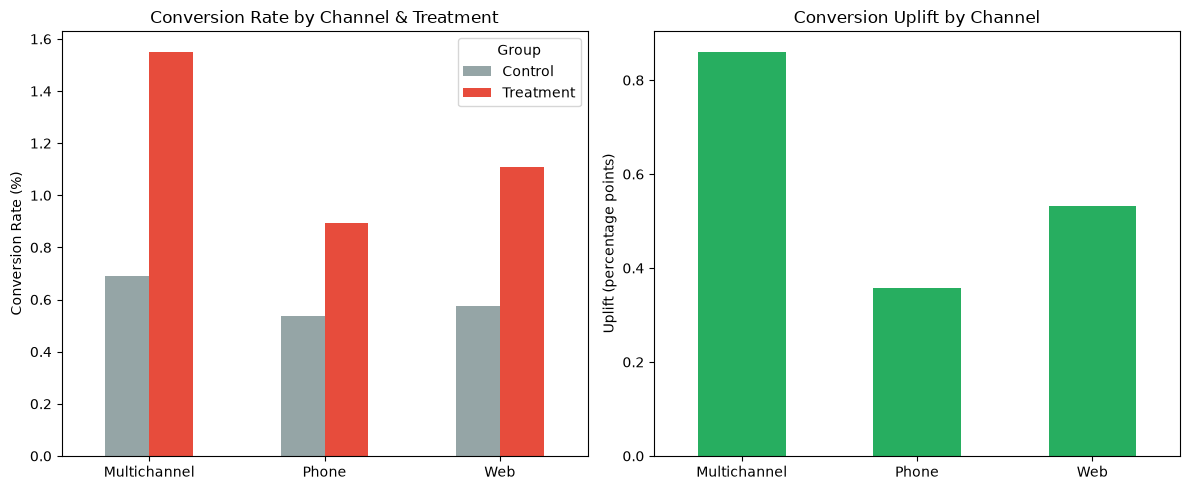

Saved to artifacts/plots/conversion_uplift_by_channel.png


In [12]:
# ── Cell 12: Visualization — Conversion Uplift by Channel ─
# Pivot the channel data and plot the uplift per channel.

pivot = df_channel.pivot(index='channel', columns='treatment', values='conversion_rate_pct')
pivot.columns = ['Control', 'Treatment']
pivot['Uplift'] = pivot['Treatment'] - pivot['Control']

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart: Treatment vs Control
pivot[['Control', 'Treatment']].plot(kind='bar', ax=axes[0], color=['#95a5a6', '#e74c3c'])
axes[0].set_title('Conversion Rate by Channel & Treatment')
axes[0].set_ylabel('Conversion Rate (%)')
axes[0].set_xlabel('')
axes[0].legend(title='Group')
axes[0].tick_params(axis='x', rotation=0)

# Uplift bar chart
colors = ['#27ae60' if x > 0 else '#e74c3c' for x in pivot['Uplift']]
pivot['Uplift'].plot(kind='bar', ax=axes[1], color=colors)
axes[1].set_title('Conversion Uplift by Channel')
axes[1].set_ylabel('Uplift (percentage points)')
axes[1].set_xlabel('')
axes[1].axhline(y=0, color='black', linewidth=0.5)
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('../artifacts/plots/conversion_uplift_by_channel.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to artifacts/plots/conversion_uplift_by_channel.png')

In [13]:
# ── Cell 13: CTE + Window — Zip Code Percentile Analysis ─
# Combine CTEs with PERCENT_RANK() to see where each
# zip_code group falls in the overall spend distribution.
#
# PERCENT_RANK() returns a value between 0 and 1,
# representing the relative rank as a percentage.

sql("""
WITH zip_stats AS (
    SELECT
        CASE c.zip_code
            WHEN 0 THEN 'Rural'
            WHEN 1 THEN 'Suburban'
            WHEN 2 THEN 'Urban'
        END AS zip_label,
        a.treatment,
        AVG(o.spend) AS avg_spend,
        AVG(CAST(o.conversion AS FLOAT)) * 100 AS conversion_pct
    FROM dbo.customers c
    INNER JOIN dbo.campaign_assignments a ON c.customer_id = a.customer_id
    INNER JOIN dbo.outcomes o             ON c.customer_id = o.customer_id
    GROUP BY c.zip_code, a.treatment
)
SELECT
    zip_label,
    treatment,
    ROUND(avg_spend, 2)      AS avg_spend,
    ROUND(conversion_pct, 2) AS conversion_pct,
    ROUND(
        PERCENT_RANK() OVER (ORDER BY avg_spend) * 100, 1
    ) AS spend_percentile
FROM zip_stats
ORDER BY zip_label, treatment
""")

,zip_label,treatment,avg_spend,conversion_pct,spend_percentile
0,Rural,0,0.69,0.58,33.3
1,Rural,1,1.22,1.06,66.7
2,Urban,0,0.59,0.56,0.0
3,Urban,1,1.29,1.07,100.0


In [14]:
# ── Cell 14: Summary Statistics for Portfolio ────────────
# A comprehensive summary query that would impress in an interview.
# Uses multiple CTEs chained together.

df_summary = sql("""
WITH overall AS (
    SELECT
        COUNT(*)            AS total_customers,
        SUM(CAST(o.visit      AS INT)) AS total_visits,
        SUM(CAST(o.conversion AS INT)) AS total_conversions,
        SUM(o.spend)                   AS total_spend
    FROM dbo.outcomes o
),
by_treatment AS (
    SELECT
        a.treatment,
        COUNT(*) AS n,
        AVG(CAST(o.visit AS FLOAT))      AS visit_rate,
        AVG(CAST(o.conversion AS FLOAT)) AS conv_rate,
        AVG(o.spend)                     AS avg_spend
    FROM dbo.campaign_assignments a
    INNER JOIN dbo.outcomes o ON a.customer_id = o.customer_id
    GROUP BY a.treatment
)
SELECT
    ov.total_customers,
    ov.total_visits,
    ov.total_conversions,
    ROUND(ov.total_spend, 2)                              AS total_spend,
    ROUND(t1.visit_rate  - t0.visit_rate, 4)              AS visit_uplift,
    ROUND(t1.conv_rate   - t0.conv_rate, 4)               AS conversion_uplift,
    ROUND(t1.avg_spend   - t0.avg_spend, 2)               AS spend_uplift
FROM overall ov
CROSS JOIN (SELECT * FROM by_treatment WHERE treatment = 0) t0
CROSS JOIN (SELECT * FROM by_treatment WHERE treatment = 1) t1
""")

print("=" * 50)
print("  Hillstrom Campaign Summary")
print("=" * 50)
for col in df_summary.columns:
    print(f"  {col:25s}: {df_summary[col].iloc[0]}")
print("\nPositive uplift = email campaign INCREASED that metric.")

  Hillstrom Campaign Summary
  total_customers          : 64000
  total_visits             : 9394
  total_conversions        : 578
  total_spend              : 67258.13
  visit_uplift             : 0.0609
  conversion_uplift        : 0.005
  spend_uplift             : 0.6

Positive uplift = email campaign INCREASED that metric.


In [15]:
# ── Cell 15: Cleanup ────────────────────────────────────
engine.dispose()
print("Connection closed. Phase 3 SQL analytics complete!")

Connection closed. Phase 3 SQL analytics complete!
